In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47435/4249902799.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')


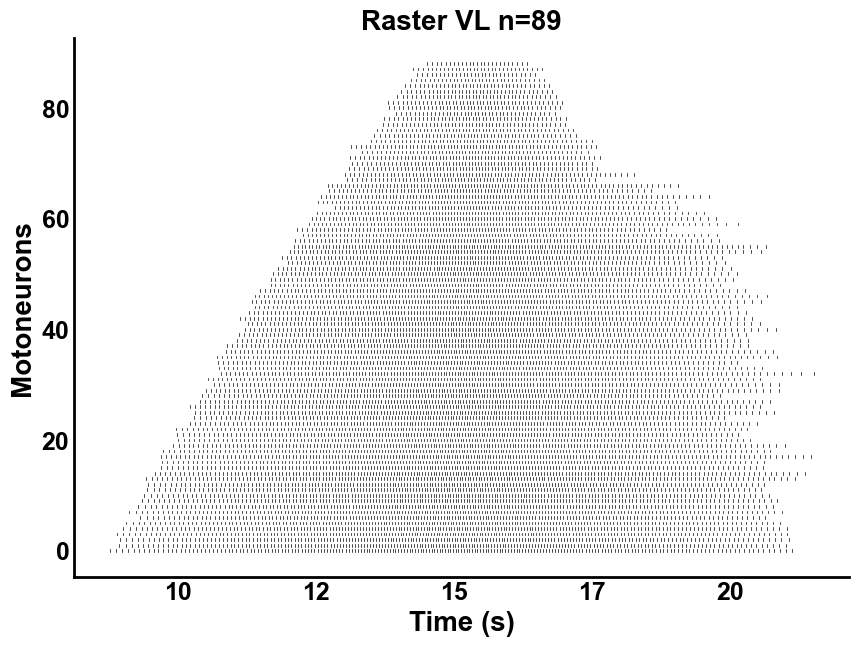

In [7]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/DR_Trapezoid_VL.jld2"

with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]

n_times, n_neurons = spike_array.shape

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

horizontal_offset = 100  # Adjust this value as needed to separate the spikes

# Plot spikes
for neuron in range(n_neurons):
    for t in range(n_times):
        if spike_array[t, neuron] == 1.0:
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * neuron
            ax.plot([t + x_offset, t + x_offset], [neuron - line_height / 2, neuron + line_height / 2], 
                    color='black', linewidth=line_thickness)

# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_title("Raster VL n=89",fontsize=20, fontweight='bold')

x_ticks = ax.get_xticks()  # Get current tick locations
ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')

# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')

# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# Show the plot
# plt.savefig('/Users/nmt121/Desktop/figures/RasterVL_89MN.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


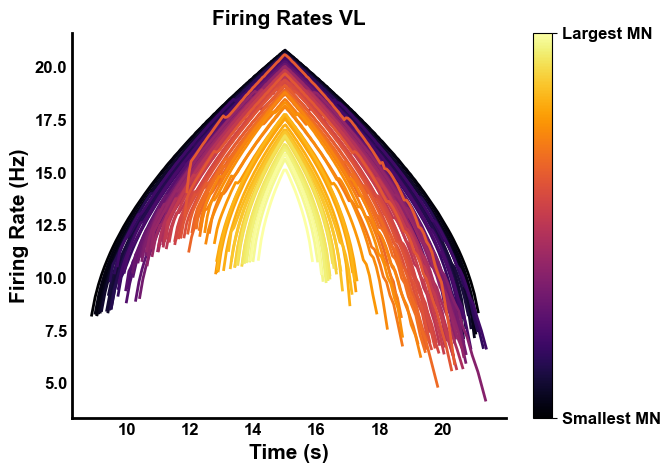

In [124]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/allratesVL.jld2"

with h5py.File(file_path, 'r') as f:
    all_rates = f['new_all_rates'][:]

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/alltimebasesVL.jld2"

with h5py.File(file_path, 'r') as f:
    all_timebases = f['new_all_bases'][:]


# Create a color map using inferno and then discretize it into 87 colors
cmap = plt.get_cmap('inferno')
discrete_cmap = cmap(np.linspace(0, 1, 89))

# Normalize the color range based on the number of motor neurons (87)
norm = Normalize(vmin=0, vmax=88)

# Create a figure and axis
fig, ax = plt.subplots(figsize=(7, 5))

# Plot each firing rate time series with corresponding color
for i in range(89):
    ax.plot(all_timebases[:, i], all_rates[:, i], color=discrete_cmap[i], linewidth=2)

# Set labels and title with Arial font
ax.set_xlabel("Time (s)", fontsize=15, fontweight='bold', fontname='Arial')
ax.set_ylabel("Firing Rate (Hz)", fontsize=15, fontweight='bold', fontname='Arial')
ax.set_title("Firing Rates VL", fontsize=15, fontweight='bold', fontname='Arial')

# Customize ticks with Arial font and remove tick marks
ax.tick_params(axis='both', length=0)
plt.xticks(fontsize=12, fontweight='bold', fontname='Arial')
plt.yticks(fontsize=12, fontweight='bold', fontname='Arial')

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
import seaborn as sns
sns.despine()

# Set the linewidth of the bottom and left spines
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Create the color bar
sm = plt.cm.ScalarMappable(cmap=plt.get_cmap('inferno'), norm=norm)
sm.set_array([])  # The array is just for the color bar, can be left empty

# Add the color bar to the plot
cbar = plt.colorbar(sm, ax=ax)

# Set the color bar ticks to display only two values
cbar.set_ticks([0, 88])
cbar.set_ticklabels(['Smallest MN', 'Largest MN'],fontsize=12, fontweight='bold', fontname='Arial')

# Move the color bar label closer and set the vertical alignment
# cbar.set_label('Motoneuron', fontsize=12, fontweight='bold', fontname='Arial', labelpad=-40)


# Save the figure in high quality
plt.savefig('/Users/nmt121/Desktop/figures/FiringRatesComparisonVL.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


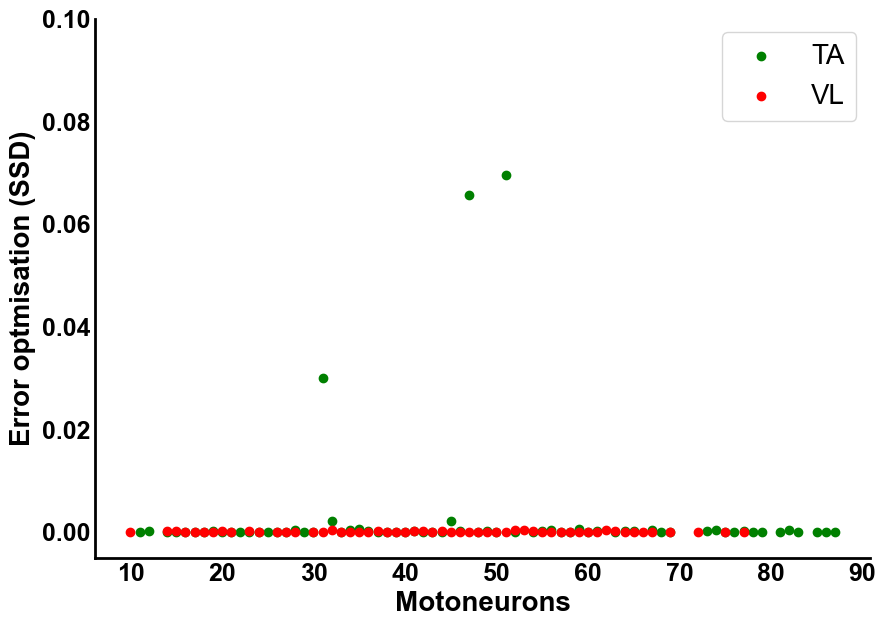

In [82]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_TA_6sept.jld2"

with h5py.File(file_path, 'r') as f:
    s1 = f['sorted_minimum_values'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_TA_6sept.jld2"

with h5py.File(file_path, 'r') as f:
    s11 = f['sorted_neuron_indices'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_VL_7sept.jld2"

with h5py.File(file_path, 'r') as f:
    s2 = f['sorted_minimum_values'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_VL_7sept.jld2"

with h5py.File(file_path, 'r') as f:
    s22 = f['sorted_neuron_indices'][:]
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(s11,s1,c='green')
plt.scatter(s22,s2,c='red')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Error optmisation (SSD)",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

plt.legend(['TA','VL'],fontsize=20)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/Error_Optim_scatter.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


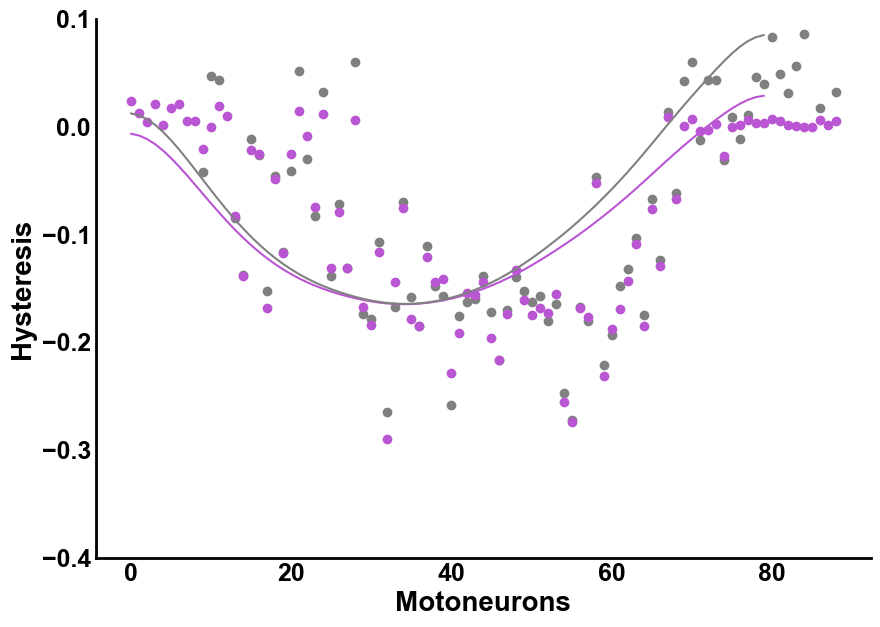

In [147]:


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_VL_exp.jld2" 

with h5py.File(file_path, 'r') as f:
    exp_hyst = f['hyst_exp'][:]
    


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_VL.jld2"

with h5py.File(file_path, 'r') as f:
    sim_hyst = f['hysteresis'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitVL_sim.jld2"

with h5py.File(file_path, 'r') as f:
    polys = f['y_fit_hysteresis_s'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitVL_exp.jld2"

with h5py.File(file_path, 'r') as f:
    polye = f['y_fit_hysteresis'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(range(0,89),exp_hyst,c='gray')
plt.scatter(range(0,89),sim_hyst[:,0],c='mediumorchid')
plt.plot(gaussian_filter1d(polys,sigma=4),c='mediumorchid')
plt.plot(gaussian_filter1d(polye,sigma=4),c='gray')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Hysteresis",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  
plt.ylim(-0.4,0.1)
# plt.legend(['Experimental','Simulated'],fontsize=15)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/PolyFit_VL_nolegend.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


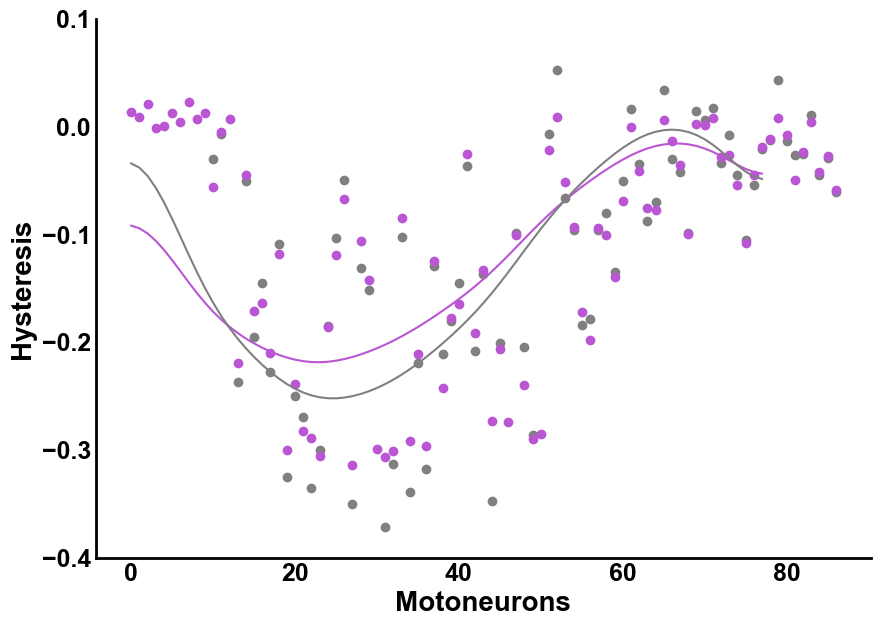

In [144]:


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA_exp.jld2" 

with h5py.File(file_path, 'r') as f:
    exp_hyst = f['hyst_exp'][:]
    


file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA.jld2"

with h5py.File(file_path, 'r') as f:
    sim_hyst = f['hysteresis'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitTA_sim.jld2"

with h5py.File(file_path, 'r') as f:
    polys = f['y_fit_hysteresis_s'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitTA_exp.jld2"

with h5py.File(file_path, 'r') as f:
    polye = f['y_fit_hysteresis'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(range(0,87),exp_hyst,c='gray')
plt.scatter(range(0,87),sim_hyst[:,0],c='mediumorchid')
plt.plot(gaussian_filter1d(polys,sigma=4),c='mediumorchid')
plt.plot(gaussian_filter1d(polye,sigma=4),c='gray')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Hysteresis",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  
plt.ylim(-0.4,0.1)
# plt.legend(['Experimental','Simulated'],fontsize=15)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/PolyFit_TA_nolegend.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()

    

In [96]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/exc_TA_MN13_14_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    exc1 = f['tr_new'][:]
    

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/force_TA_MN13_14_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    force = f['force'][:]
    
    
file_path = "Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/inh_TA_MN13_14_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    inh = f['inh_input'][:]
    
    
file_path = "Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/originaltrajectory_TA_MN13_14_inh_PICstart"

with h5py.File(file_path, 'r') as f:
    original = f['trajectory2_controlled'][:]
    
file_path = "Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/trajectory_controlled_TA_MN13_14_inh_PICstart.jld2"

with h5py.File(file_path, 'r') as f:
    new = f['trajectory2_controlled'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/force_derivative.jld2"

with h5py.File(file_path, 'r') as f:
    force_derivative = f['force_derivative'][:]
    
    
    

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6937/554494596.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('cool', new.shape[1])  # Using binary colormap


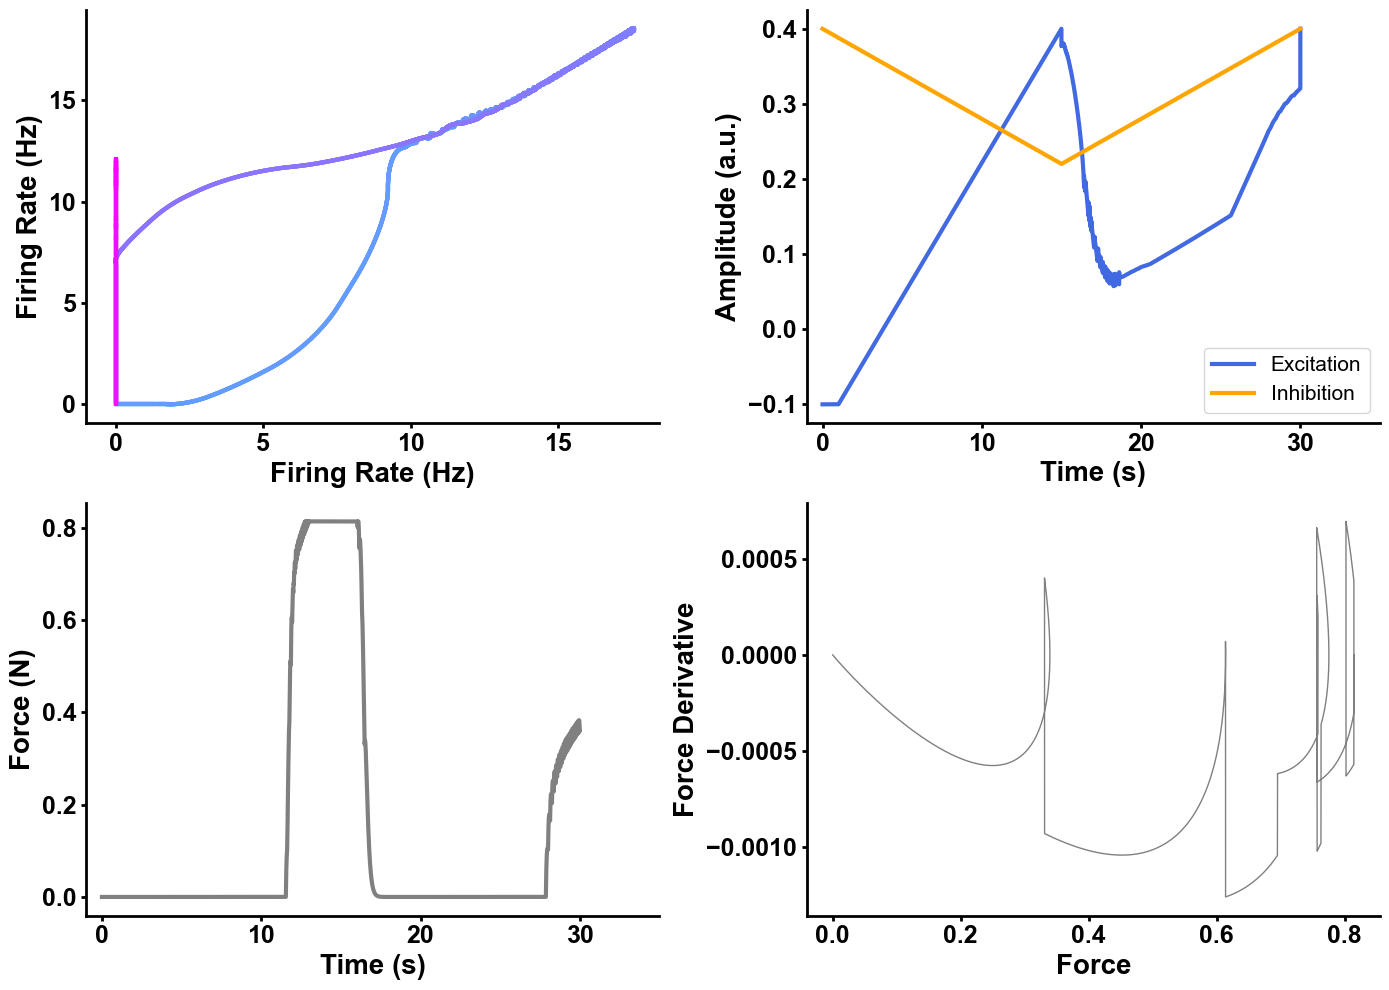

In [97]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Set font to Arial for all plots
plt.rcParams['font.family'] = 'Arial'

# Create a figure with 2x2 subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

cmap = cm.get_cmap('cool', new.shape[1])  # Using binary colormap

# First subplot: New Trajectory with gradient from binary colormap
for i in range(new.shape[1] - 1):
    axs[0, 0].plot(new[0, i:i+2], new[1, i:i+2], color=cmap(i / new.shape[1]), linewidth=3)

axs[0, 0].set_xlabel("Firing Rate (Hz)", fontsize=20, fontweight='bold')
axs[0, 0].set_ylabel("Firing Rate (Hz)", fontsize=20, fontweight='bold')
# axs[0, 0].set_title("Original and New Trajectory", fontsize=22, fontweight='bold')
axs[0, 0].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black', labelrotation=0)
axs[0, 0].grid(False)
axs[0, 0].set_xlim(left=-1)

# Second subplot: Excitation and Inhibition
axs[0, 1].plot(exc1, label='Excitation', color='royalblue', linewidth=3)
axs[0, 1].plot(inh, label='Inhibition', color='orange', linewidth=3)
axs[0, 1].set_xlabel("Time (s)", fontsize=20, fontweight='bold')
axs[0, 1].set_ylabel("Amplitude (a.u.)", fontsize=20, fontweight='bold')
axs[0, 1].legend(fontsize=15)
axs[0, 1].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')
axs[0, 1].set_xticks(axs[0, 1].get_xticks())
axs[0, 1].set_xticklabels([f'{int(x/1000)}' for x in axs[0, 1].get_xticks()], fontsize=18, fontweight='bold')
axs[0, 1].set_xlim(-1000, 35000)
axs[0, 1].grid(False)

# Third subplot: Force
axs[1, 0].plot(force, color='gray', label='Force', linewidth=3)
axs[1, 0].set_xlabel("Time (s)", fontsize=20, fontweight='bold')
axs[1, 0].set_ylabel("Force (N)", fontsize=20, fontweight='bold')
axs[1, 0].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')
axs[1, 0].set_xticks(axs[1, 0].get_xticks())
axs[1, 0].set_xticklabels([f'{int(x/20000)}' for x in axs[1, 0].get_xticks()], fontsize=18, fontweight='bold')
axs[1, 0].grid(False)
axs[1, 0].set_xlim(-20000, 700000)

# Fourth subplot: Force and Force Derivative (zoomed)
axs[1, 1].plot(force[300000:450000], force_derivative[300000:450000], color='gray', linewidth=1)
axs[1, 1].set_xlabel("Force", fontsize=20, fontweight='bold')
axs[1, 1].set_ylabel("Force Derivative", fontsize=20, fontweight='bold')
axs[1, 1].tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')
axs[1, 1].grid(False)

# Make axis spines thicker and set tick labels bold for all subplots
for ax in axs.flat:
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['left'].set_linewidth(2)
    for tick in ax.get_xticklabels():
        tick.set_fontsize(18)
        tick.set_fontweight('bold')
    for tick in ax.get_yticklabels():
        tick.set_fontsize(18)
        tick.set_fontweight('bold')

# Adjust layout and appearance
plt.tight_layout()
sns.despine()
plt.savefig('/Users/nmt121/Desktop/figures/Controller_changingINH_PICstart_2loop_1314.png', dpi=300, bbox_inches='tight')

# Show plot
plt.show()




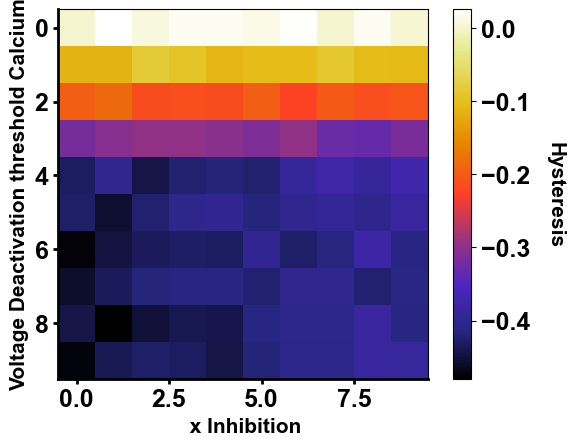

In [95]:
import matplotlib.pyplot as plt
import h5py

# Load the hysteresis data from the .jld2 file
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap1_balanced.jld2"
with h5py.File(file_path, 'r') as f:
    hyst = f['hysteresis_for_each_inh'][:].T

# Set font to Arial and apply consistent styling
plt.rcParams['font.family'] = 'Arial'

# Create the heatmap plot with the CMRmap colormap
plt.imshow(hyst, cmap='CMRmap')

# Set the x and y labels with the same font size and weight as before
plt.xlabel(" x Inhibition", fontsize=15, fontweight='bold')
plt.ylabel("Voltage Deactivation threshold Calcium", fontsize=15, fontweight='bold')

# Add a colorbar and customize its font size
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=18)

# Set colorbar tick labels to bold
for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')

# Customize tick parameters (font size, width, color, and fontweight for bold numbers)
plt.tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')

# Manually set the fontweight of the tick labels to bold
ax = plt.gca()  # Get current axis
for tick in ax.get_xticklabels():
    tick.set_fontweight('bold')
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make axis spines thicker for consistency
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', which='both', length=0)

# Disable grid to match previous plots
plt.grid(False)

# Display the plot
cbar.set_label('Hysteresis', fontsize=15, fontweight='bold', fontname='Arial', rotation=270, labelpad=25)


plt.savefig('/Users/nmt121/Desktop/figures/HeatmapMN1_balanced.png', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()



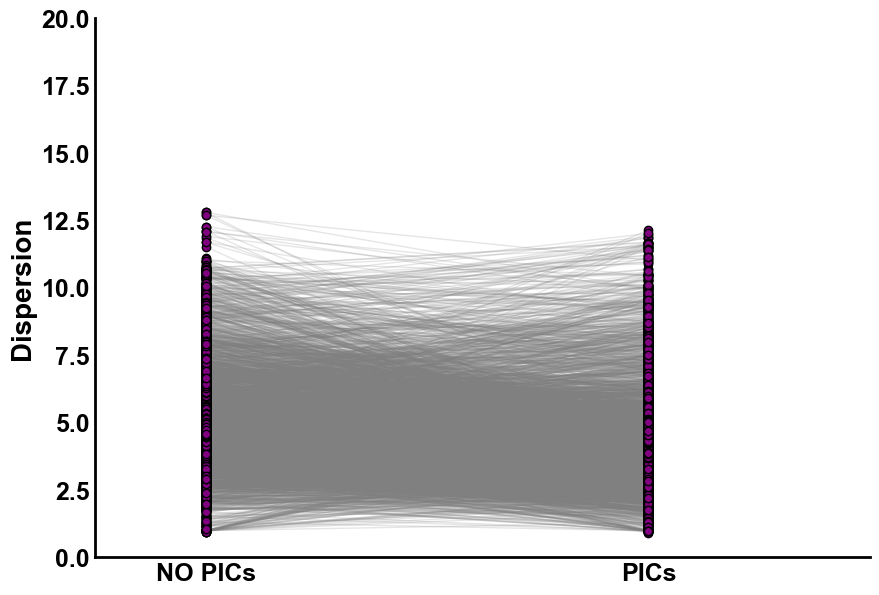

In [140]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/dispersion_chirp_NOPIC.mat"
mat_data = scipy.io.loadmat(file_path)
dispersion_NOPIC = mat_data['dispersion'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/dispersion_chirp_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
dispersion_PIC = mat_data['dispersion'][0,:]

# Set plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(dispersion_PIC)):
    plt.plot([2, 6], [dispersion_NOPIC[i], dispersion_PIC[i]], 'gray', linewidth=1, alpha=0.2)  # Line with transparency

# Now plot the scatter plot for PIC and NOPIC after drawing the lines
plt.scatter(np.ones(len(dispersion_NOPIC))*2, dispersion_NOPIC, c='purple', edgecolors='black', zorder=3, label='PIC')
plt.scatter(np.ones(len(dispersion_NOPIC))*6, dispersion_PIC, c='purple', edgecolors='black', zorder=3, label='NOPIC')

# Set axis labels
ax.set_ylabel("Dispersion", fontsize=20, fontweight='bold')

# Customize x-ticks to show "NOPIC" and "PIC"
plt.xticks([2, 6], ['NO PICs', 'PICs'], fontsize=18, fontweight='bold')  # Customize x-tick labels
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([0, 20])
plt.xlim([1, 8])

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()
ax.tick_params(axis='both', which='both', length=0)

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)

plt.savefig('/Users/nmt121/Desktop/figures/dispersion_chirp.png', dpi=300, bbox_inches='tight')


# Display the plot
plt.show()




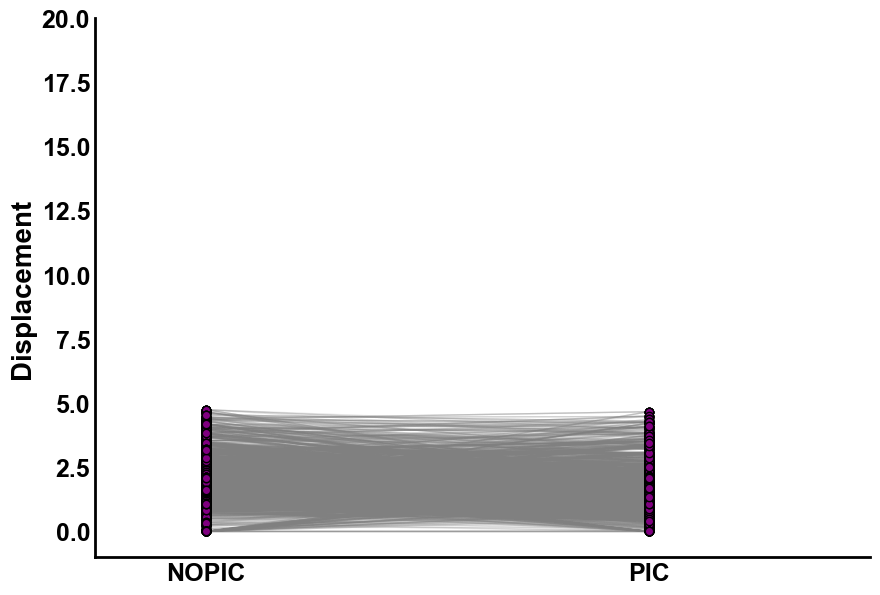

In [141]:
# Load the data
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_chirp_NOPIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_NOPIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_chirp_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_PIC = mat_data['displacement'][0,:]

# Set plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(dispersion_PIC)):
    plt.plot([2, 6], [displacement_NOPIC[i], displacement_PIC[i]], 'gray', linewidth=1, alpha=0.2)  # Line with transparency

# Now plot the scatter plot for PIC and NOPIC after drawing the lines
plt.scatter(np.ones(len(displacement_NOPIC))*2, displacement_NOPIC, c='purple', edgecolors='black', zorder=3, label='PIC')
plt.scatter(np.ones(len(displacement_PIC))*6, displacement_PIC, c='purple', edgecolors='black', zorder=3, label='NOPIC')

# Set axis labels
ax.set_ylabel("Displacement", fontsize=20, fontweight='bold')

# Customize x-ticks to show "NOPIC" and "PIC"
plt.xticks([2, 6], ['NOPIC', 'PIC'], fontsize=18, fontweight='bold')  # Customize x-tick labels
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-1, 20])
plt.xlim([1, 8])

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()

# Customize axis line thickness
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', which='both', length=0)

plt.savefig('/Users/nmt121/Desktop/figures/displacement_chirp.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6937/3601837442.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')


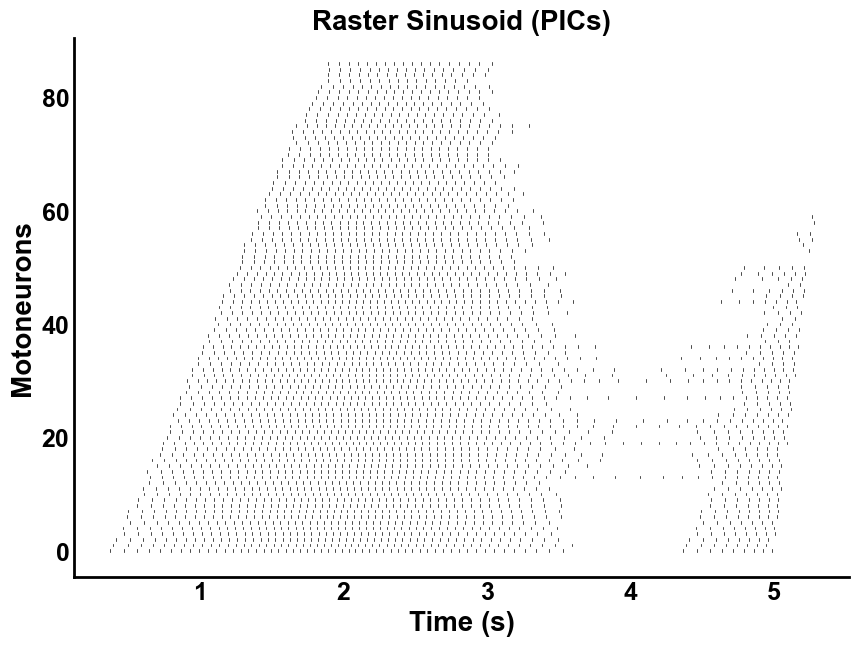

In [149]:
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/DR_Sinusoid_025.mat"

with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]

n_times, n_neurons = spike_array.shape

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

horizontal_offset = 100  # Adjust this value as needed to separate the spikes

# Plot spikes
for neuron in range(n_neurons):
    for t in range(n_times):
        if spike_array[t, neuron] == 1.0:
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * neuron
            ax.plot([t + x_offset, t + x_offset], [neuron - line_height / 2, neuron + line_height / 2], 
                    color='black', linewidth=line_thickness)

# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_title("Raster Sinusoid (PICs)",fontsize=20, fontweight='bold')

x_ticks = ax.get_xticks()  # Get current tick locations
ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')

# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')

# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/RasterSinusoid_PIC_TA.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()
